## Manual Euclidean and Cosine calculations

In [ ]:
import math
import numpy as np
import os
from dotenv import load_dotenv
from qdrant_client import QdrantClient
import time
from qdrant_client import models
from qdrant_client.models import Distance, VectorParams, PointStruct

In [5]:
# Define three stored 2D vectors
points = {
    "A": (2, 3),
    "B": (1, 2),
    "C": (0, 4)
}

# Define the query vector
query = (2, 4)

print("Stored Vectors:", points)
print("Query Vector:", query)

Stored Vectors: {'A': (2, 3), 'B': (1, 2), 'C': (0, 4)}
Query Vector: (2, 4)


In [6]:
# Calculate straight-line distance between two vectors
def euclidean_distance(v1, v2):
    return math.sqrt(
        sum((a - b) ** 2 for a, b in zip(v1, v2))
    )

In [7]:
# Calculate directional similarity between two vectors
def cosine_similarity(v1, v2):
    dot_product = sum(a * b for a, b in zip(v1, v2))

    magnitude1 = math.sqrt(sum(a ** 2 for a in v1))
    magnitude2 = math.sqrt(sum(b ** 2 for b in v2))

    return dot_product / (magnitude1 * magnitude2)

In [10]:
# Calculate both metrics for every stored vector
euclidean_results = []
cosine_results = []

for name, vector in points.items():

    distance = euclidean_distance(query, vector)
    similarity = cosine_similarity(query, vector)

    euclidean_results.append((name, distance))
    cosine_results.append((name, similarity))


# Sort by smallest distance and highest similarity
euclidean_results.sort(key=lambda x: x[1])
cosine_results.sort(key=lambda x: x[1], reverse=True)

print("Stored Vectors:", points)
print("Query Vector:", query)

# Display Euclidean ranking
print("\nEuclidean Distance Ranking:")

for name, score in euclidean_results:
    print(f"{name}: {score:.4f}")


# Display Cosine similarity ranking
print("\nCosine Similarity Ranking:")

for name, score in cosine_results:
    print(f"{name}: {score:.4f}")

Stored Vectors: {'A': (2, 3), 'B': (1, 2), 'C': (0, 4)}
Query Vector: (2, 4)

Euclidean Distance Ranking:
A: 1.0000
C: 2.0000
B: 2.2361

Cosine Similarity Ranking:
B: 1.0000
A: 0.9923
C: 0.8944


Euclidean Distance: Measures the straight-line distance between vectors. Point A has the smallest distance (1.0), making it the closest match.

Cosine Similarity: Measures the directional similarity between vectors. Point B scores 1.0 because it has exactly the same direction as the query.

Key Observation: Euclidean ranks A first, while Cosine ranks B first. Euclidean considers distance and magnitude, whereas Cosine focuses on direction. Therefore, the same query can produce different rankings depending on the similarity metric.

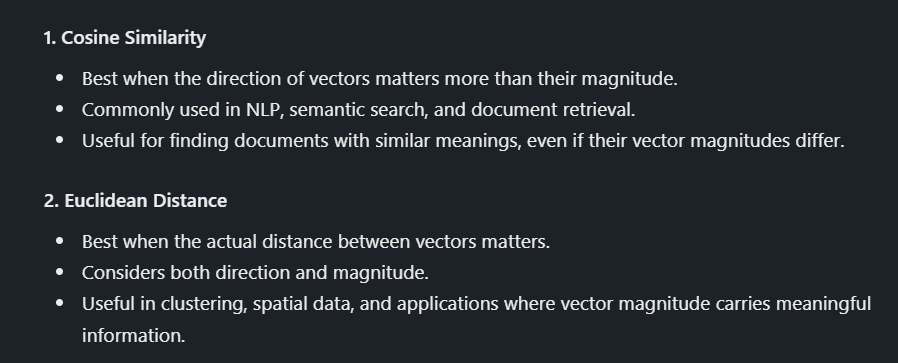

## NumPy brute-force vector search

Brute-force search means comparing the query vector against every stored vector, one by one, to find the closest matches.

1. Retrieve Gemini Embedding 2 vectors from the existing SENTINEL Qdrant collection.
2. Store the vectors in a NumPy array.
3. Accept a query vector.
4. Calculate Euclidean distance against every stored vector.
5. Calculate cosine similarity against every stored vector.
6. Return the Top-K most relevant results for both metrics.

In [13]:
# Load existing Qdrant credentials
load_dotenv()

QDRANT_URL = os.getenv("QDRANT_URL")
QDRANT_KEY = os.getenv("QDRANT_KEY")

# Connect to Qdrant Cloud
client = QdrantClient(
    url=QDRANT_URL,
    api_key=QDRANT_KEY
)

# Check the Qdrant connection
print(client.get_collections())

collections=[CollectionDescription(name='sentinel_documents_gemini2')]


In [14]:
# Select the existing SENTINEL collection
COLLECTION_NAME = "sentinel_documents_gemini2"

# Display collection information
collection_info = client.get_collection(COLLECTION_NAME)

print("Collection:", COLLECTION_NAME)
print("Total Points:", collection_info.points_count)
print("Vector Configuration:", collection_info.config.params.vectors)

Collection: sentinel_documents_gemini2
Total Points: 800
Vector Configuration: size=3072 distance=<Distance.COSINE: 'Cosine'> hnsw_config=None quantization_config=None on_disk=None memory=None datatype=None multivector_config=None


In [ ]:
# Retrieve up to 1000 stored vectors or the total number of points in the collection
MAX_VECTORS = 1000

all_points = []
offset = None

while len(all_points) < MAX_VECTORS:

    batch_size = min(256, MAX_VECTORS - len(all_points))

    # Fetch vectors and metadata from Qdrant
    points_batch, offset = client.scroll(
        collection_name=COLLECTION_NAME,
        limit=batch_size,
        offset=offset,
        with_vectors=True,
        with_payload=True
    )

    all_points.extend(points_batch)

    if offset is None:
        break


print("Retrieved Points:", len(all_points))

Retrieved Points: 800


In [16]:
# Extract vector IDs and embeddings
point_ids = [point.id for point in all_points]

vectors_list = []

for point in all_points:

    vector = point.vector

    # Handle both named and unnamed vectors
    if isinstance(vector, dict):
        vector = next(iter(vector.values()))

    vectors_list.append(vector)


# Convert embeddings into a NumPy matrix
vectors = np.asarray(vectors_list, dtype=np.float32)

print("Vector Matrix Shape:", vectors.shape)
print("Number of Vectors:", len(vectors))
print("Embedding Dimensions:", vectors.shape[1])

Vector Matrix Shape: (800, 3072)
Number of Vectors: 800
Embedding Dimensions: 3072


In [17]:
# Search every stored vector and return the Top-K matches
def brute_force_search(query_vector, stored_vectors, point_ids, k=5, metric="cosine"):

    # Convert query into a NumPy array
    query_vector = np.asarray(query_vector, dtype=np.float32)

    if metric == "euclidean":

        # Calculate distance from query to every stored vector
        scores = np.linalg.norm(stored_vectors - query_vector, axis=1)

        # Select vectors with the smallest distances
        indices = np.argsort(scores)[:k]

    elif metric == "cosine":

        # Calculate dot products and vector magnitudes
        dot_products = stored_vectors @ query_vector

        query_norm = np.linalg.norm(query_vector)
        vector_norms = np.linalg.norm(stored_vectors, axis=1)

        # Calculate cosine similarity safely
        denominators = vector_norms * query_norm

        scores = np.divide(
            dot_products,
            denominators,
            out=np.zeros_like(denominators),
            where=denominators != 0
        )

        # Select vectors with the highest similarity
        indices = np.argsort(scores)[::-1][:k]

    else:
        raise ValueError("Unsupported metric")

    # Return IDs and corresponding scores
    return [
        (point_ids[i], float(scores[i]))
        for i in indices
    ]

In [18]:
# Select an existing embedding as the query
query_vector = vectors[0]

# Define the number of results to retrieve
TOP_K = 5

# Perform Euclidean and Cosine searches
euclidean_results = brute_force_search(
    query_vector, vectors, point_ids,
    k=TOP_K, metric="euclidean"
)

cosine_results = brute_force_search(
    query_vector, vectors, point_ids,
    k=TOP_K, metric="cosine"
)


# Display Euclidean results
print("Euclidean Top-K Results:")

for point_id, score in euclidean_results:
    print(f"ID: {point_id}, Distance: {score:.6f}")


# Display Cosine results
print("\nCosine Top-K Results:")

for point_id, score in cosine_results:
    print(f"ID: {point_id}, Similarity: {score:.6f}")

Euclidean Top-K Results:
ID: 00585cda-bec7-4cb1-b4e6-5f456dd6a7fb, Distance: 0.000000
ID: 86385782-769e-4631-8603-f2d1f5322211, Distance: 0.228265
ID: 91638ac5-39d2-46bb-9274-33cfe1927f2b, Distance: 0.280625
ID: 52835238-d505-4df3-af98-7384dd8bb803, Distance: 0.331212
ID: a4117f4f-4f76-4318-b155-d3bfc235890d, Distance: 0.337176

Cosine Top-K Results:
ID: 00585cda-bec7-4cb1-b4e6-5f456dd6a7fb, Similarity: 1.000000
ID: 86385782-769e-4631-8603-f2d1f5322211, Similarity: 0.973948
ID: 91638ac5-39d2-46bb-9274-33cfe1927f2b, Similarity: 0.960625
ID: 52835238-d505-4df3-af98-7384dd8bb803, Similarity: 0.945149
ID: a4117f4f-4f76-4318-b155-d3bfc235890d, Similarity: 0.943156


## Qdrant vs NumPy comparison

In [20]:
# Retrieve existing collection configuration
collection_info = client.get_collection(
    collection_name="sentinel_documents_gemini2"
)

# Display vector configuration
print("Collection:", "sentinel_documents_gemini2")
print("Total Points:", collection_info.points_count)
print("Vector Configuration:", collection_info.config.params.vectors)

Collection: sentinel_documents_gemini2
Total Points: 800
Vector Configuration: size=3072 distance=<Distance.COSINE: 'Cosine'> hnsw_config=None quantization_config=None on_disk=None memory=None datatype=None multivector_config=None


In [21]:
# Perform exact Cosine search using Qdrant
qdrant_results = client.query_points(
    collection_name="sentinel_documents_gemini2",
    query=query_vector.tolist(),
    limit=TOP_K,
    search_params=models.SearchParams(exact=True)
)

# Display the Top-K search results
print("Qdrant Cosine Top-K Results:\n")

for point in qdrant_results.points:
    print(f"ID: {point.id}, Score: {point.score:.6f}")

Qdrant Cosine Top-K Results:

ID: 00585cda-bec7-4cb1-b4e6-5f456dd6a7fb, Score: 1.000000
ID: 86385782-769e-4631-8603-f2d1f5322211, Score: 0.973948
ID: 91638ac5-39d2-46bb-9274-33cfe1927f2b, Score: 0.960625
ID: 52835238-d505-4df3-af98-7384dd8bb803, Score: 0.945149
ID: a4117f4f-4f76-4318-b155-d3bfc235890d, Score: 0.943156


In [ ]:
# Extract result IDs from Qdrant
qdrant_ids = [
    point.id for point in qdrant_results.points
]

# Extract result IDs from NumPy
numpy_ids = [
    point_id for point_id, score in cosine_results
]

# Compare both rankings
print("NumPy Top-K IDs:")
print(numpy_ids)

print("\nQdrant Top-K IDs:")
print(qdrant_ids)

# Check whether both rankings match
print("\nRanking Match:", numpy_ids == qdrant_ids)

NumPy Top-K IDs:
['00585cda-bec7-4cb1-b4e6-5f456dd6a7fb', '86385782-769e-4631-8603-f2d1f5322211', '91638ac5-39d2-46bb-9274-33cfe1927f2b', '52835238-d505-4df3-af98-7384dd8bb803', 'a4117f4f-4f76-4318-b155-d3bfc235890d']

Qdrant Top-K IDs:
['00585cda-bec7-4cb1-b4e6-5f456dd6a7fb', '86385782-769e-4631-8603-f2d1f5322211', '91638ac5-39d2-46bb-9274-33cfe1927f2b', '52835238-d505-4df3-af98-7384dd8bb803', 'a4117f4f-4f76-4318-b155-d3bfc235890d']

Ranking Match: True


In [23]:
# Compare NumPy and Qdrant Cosine scores
print("ID | NumPy Score | Qdrant Score")

for (numpy_id, numpy_score), qdrant_point in zip(
    cosine_results, qdrant_results.points
):
    print(
        f"{numpy_id} | "
        f"{numpy_score:.6f} | "
        f"{qdrant_point.score:.6f}"
    )

ID | NumPy Score | Qdrant Score
00585cda-bec7-4cb1-b4e6-5f456dd6a7fb | 1.000000 | 1.000000
86385782-769e-4631-8603-f2d1f5322211 | 0.973948 | 0.973948
91638ac5-39d2-46bb-9274-33cfe1927f2b | 0.960625 | 0.960625
52835238-d505-4df3-af98-7384dd8bb803 | 0.945149 | 0.945149
a4117f4f-4f76-4318-b155-d3bfc235890d | 0.943156 | 0.943156


The experiment confirms that our NumPy brute-force Cosine Similarity implementation produces the same results as Qdrant's exact vector search.

## Vector normalization

In [24]:
# Calculate the magnitude of each stored vector
vector_norms = np.linalg.norm(vectors, axis=1, keepdims=True)

# Normalize stored vectors
normalized_vectors = vectors / np.maximum(vector_norms, 1e-12)

# Normalize the query vector
query_norm = np.linalg.norm(query_vector)
normalized_query = query_vector / max(query_norm, 1e-12)

print("Original Vector Shape:", vectors.shape)
print("Normalized Vector Shape:", normalized_vectors.shape)
print("Normalized Query Magnitude:", np.linalg.norm(normalized_query))

Original Vector Shape: (800, 3072)
Normalized Vector Shape: (800, 3072)
Normalized Query Magnitude: 1.0


In [25]:
# Calculate dot product for normalized vectors
dot_scores = normalized_vectors @ normalized_query

# Calculate cosine similarity for normalized vectors
cosine_scores = normalized_vectors @ normalized_query

# Get Top-5 results for both metrics
dot_indices = np.argsort(dot_scores)[::-1][:TOP_K]
cosine_indices = np.argsort(cosine_scores)[::-1][:TOP_K]

print("Dot Product Top-K Results:")
for i in dot_indices:
    print(point_ids[i], round(float(dot_scores[i]), 6))

print("\nCosine Similarity Top-K Results:")
for i in cosine_indices:
    print(point_ids[i], round(float(cosine_scores[i]), 6))

Dot Product Top-K Results:
00585cda-bec7-4cb1-b4e6-5f456dd6a7fb 1.0
86385782-769e-4631-8603-f2d1f5322211 0.973948
91638ac5-39d2-46bb-9274-33cfe1927f2b 0.960625
52835238-d505-4df3-af98-7384dd8bb803 0.945149
a4117f4f-4f76-4318-b155-d3bfc235890d 0.943156

Cosine Similarity Top-K Results:
00585cda-bec7-4cb1-b4e6-5f456dd6a7fb 1.0
86385782-769e-4631-8603-f2d1f5322211 0.973948
91638ac5-39d2-46bb-9274-33cfe1927f2b 0.960625
52835238-d505-4df3-af98-7384dd8bb803 0.945149
a4117f4f-4f76-4318-b155-d3bfc235890d 0.943156


When vectors are normalized to unit length, Dot Product and Cosine Similarity produce identical scores and rankings. This is because the magnitude of each vector becomes 1.

## Performance benchmarking (1,000 and 10,000 vectors)

In [43]:
# Benchmark configuration
VECTOR_SIZE = 3072
DATASET_SIZES = [1000, 10000]
TOP_K = 5

# Connect to Qdrant
client = QdrantClient(
    url=QDRANT_URL,
    api_key=QDRANT_KEY,
    timeout=120
)

print("Qdrant connected successfully.")

Qdrant connected successfully.


In [44]:
# Generate reproducible random vectors
rng = np.random.default_rng(42)

# Generate query vector
benchmark_query = rng.random(VECTOR_SIZE).astype(np.float32)

# Normalize query vector
benchmark_query /= np.linalg.norm(benchmark_query)

# Generate datasets
benchmark_datasets = {}

for size in DATASET_SIZES:

    data = rng.random((size, VECTOR_SIZE)).astype(np.float32)

    # Normalize stored vectors
    norms = np.linalg.norm(data, axis=1, keepdims=True)
    data = data / np.maximum(norms, 1e-12)

    benchmark_datasets[size] = data

    print(f"{size} vectors generated: {data.shape}")

1000 vectors generated: (1000, 3072)
10000 vectors generated: (10000, 3072)


In [45]:
for size in DATASET_SIZES:

    collection_name = f"benchmark_{size}"

    # Delete only existing benchmark collections
    if client.collection_exists(collection_name):
        client.delete_collection(collection_name)

    # Create collection with default HNSW configuration
    client.create_collection(
        collection_name=collection_name,
        vectors_config=VectorParams(
            size=VECTOR_SIZE,
            distance=Distance.COSINE
        )
    )

    print(f"Created collection: {collection_name}")

Created collection: benchmark_1000
Created collection: benchmark_10000


In [46]:
for size in DATASET_SIZES:

    collection_name = f"benchmark_{size}"
    data = benchmark_datasets[size]

    points = [
        PointStruct(
            id=i,
            vector=vector.tolist()
        )
        for i, vector in enumerate(data)
    ]

    print(f"\nUploading {size} vectors...")

    # Upload in smaller batches
    client.upload_points(
        collection_name=collection_name,
        points=points,
        batch_size=50,
        wait=True
    )

    print(f"Uploaded {size} vectors successfully.")


Uploading 1000 vectors...
Uploaded 1000 vectors successfully.

Uploading 10000 vectors...
Uploaded 10000 vectors successfully.


In [47]:
for size in DATASET_SIZES:

    collection_name = f"benchmark_{size}"
    info = client.get_collection(collection_name)

    print(f"\nCollection: {collection_name}")
    print(f"Points Count: {info.points_count}")
    print(f"Indexed Vectors: {info.indexed_vectors_count}")
    print(f"Status: {info.status}")


Collection: benchmark_1000
Points Count: 1000
Indexed Vectors: 0
Status: green

Collection: benchmark_10000
Points Count: 10000
Indexed Vectors: 9350
Status: green


In [48]:
numpy_times = {}
numpy_results = {}

for size in DATASET_SIZES:

    data = benchmark_datasets[size]

    start = time.perf_counter()

    # Calculate cosine ranking using normalized vectors
    scores = data @ benchmark_query

    # Retrieve exact Top-K results
    top_indices = np.argsort(scores)[::-1][:TOP_K]

    elapsed = (time.perf_counter() - start) * 1000

    numpy_times[size] = elapsed
    numpy_results[size] = top_indices.tolist()

    print(f"\nDataset: {size} vectors")
    print(f"Top-5 IDs: {top_indices}")
    print(f"NumPy Search Time: {elapsed:.3f} ms")


Dataset: 1000 vectors
Top-5 IDs: [930 436 275 340 408]
NumPy Search Time: 22.962 ms

Dataset: 10000 vectors
Top-5 IDs: [ 993 8820 6023 7179 9474]
NumPy Search Time: 64.970 ms


In [49]:
qdrant_times = {}
qdrant_results = {}

for size in DATASET_SIZES:

    collection_name = f"benchmark_{size}"

    start = time.perf_counter()

    results = client.query_points(
        collection_name=collection_name,
        query=benchmark_query.tolist(),
        limit=TOP_K
    )

    elapsed = (time.perf_counter() - start) * 1000

    qdrant_times[size] = elapsed
    qdrant_results[size] = [point.id for point in results.points]

    print(f"\nDataset: {size} vectors")
    print(f"Top-5 IDs: {qdrant_results[size]}")
    print(f"Qdrant Search Time: {elapsed:.3f} ms")


Dataset: 1000 vectors
Top-5 IDs: [930, 436, 275, 340, 408]
Qdrant Search Time: 1010.833 ms

Dataset: 10000 vectors
Top-5 IDs: [8820, 6023, 9474, 5812, 419]
Qdrant Search Time: 356.775 ms


In [50]:
for size in DATASET_SIZES:

    numpy_ids = set(numpy_results[size])
    qdrant_ids = set(qdrant_results[size])

    matching_ids = numpy_ids.intersection(qdrant_ids)

    recall_at_5 = len(matching_ids) / TOP_K

    print(f"\nDataset: {size} vectors")
    print(f"Matching IDs: {len(matching_ids)}/{TOP_K}")
    print(f"Recall@5: {recall_at_5:.2f}")


Dataset: 1000 vectors
Matching IDs: 5/5
Recall@5: 1.00

Dataset: 10000 vectors
Matching IDs: 3/5
Recall@5: 0.60


In [51]:
print(f"{'Dataset':<15}{'NumPy (ms)':<18}{'Qdrant (ms)':<18}")

for size in DATASET_SIZES:
    print(
        f"{size:<15}"
        f"{numpy_times[size]:<18.3f}"
        f"{qdrant_times[size]:<18.3f}"
    )

Dataset        NumPy (ms)        Qdrant (ms)       
1000           22.962            1010.833          
10000          64.970            356.775           


Tested NumPy brute-force and Qdrant search on 1,000 and 10,000 vectors.

NumPy took 22.962 ms and 64.970 ms, respectively.

Qdrant took 1,010.833 ms and 356.775 ms.

Recall@5 is 1.00 for 1,000 vectors and 0.60 for 10,000 vectors.

In [52]:
# Repeat benchmark for reliable measurements
NUM_RUNS = 5

numpy_times = {}
qdrant_times = {}

for size in DATASET_SIZES:

    data = benchmark_datasets[size]
    collection_name = f"benchmark_{size}"

    numpy_runs = []
    qdrant_runs = []

    # Warm up NumPy
    _ = data @ benchmark_query

    # Warm up Qdrant
    client.query_points(
        collection_name=collection_name,
        query=benchmark_query.tolist(),
        limit=TOP_K
    )

    for _ in range(NUM_RUNS):

        # Measure NumPy brute-force search
        start = time.perf_counter()

        scores = data @ benchmark_query
        top_indices = np.argsort(scores)[::-1][:TOP_K]

        numpy_runs.append(
            (time.perf_counter() - start) * 1000
        )

        # Measure Qdrant search
        start = time.perf_counter()

        client.query_points(
            collection_name=collection_name,
            query=benchmark_query.tolist(),
            limit=TOP_K
        )

        qdrant_runs.append(
            (time.perf_counter() - start) * 1000
        )

    # Calculate median timings
    numpy_times[size] = np.median(numpy_runs)
    qdrant_times[size] = np.median(qdrant_runs)

    print(f"\nDataset: {size} vectors")
    print(f"NumPy Median: {numpy_times[size]:.3f} ms")
    print(f"Qdrant Median: {qdrant_times[size]:.3f} ms")


Dataset: 1000 vectors
NumPy Median: 0.927 ms
Qdrant Median: 362.710 ms

Dataset: 10000 vectors
NumPy Median: 6.007 ms
Qdrant Median: 364.963 ms


NumPy search time increased from 0.927 ms to 6.007 ms as the dataset grew.

Qdrant search time remained relatively stable.

NumPy was faster in this experiment because the vectors were already loaded in local memory.

Qdrant timings include cloud network latency and server processing.